<a href="https://colab.research.google.com/github/manuelrecayte/proyectos-personales/blob/main/proyecto-pcd/ProyectofinalPCD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importamos paquetes
import pandas as pd
import numpy as np
import seaborn as sn
import sklearn as sk
import matplotlib.pyplot as plt

In [ ]:
#cargamos datos
data = pd.read_csv("/datoscangrejo.csv")
data

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
0,F,1.4375,1.1750,0.4125,24.635715,12.332033,5.584852,6.747181,9
1,M,0.8875,0.6500,0.2125,5.400580,2.296310,1.374951,1.559222,6
2,I,1.0375,0.7750,0.2500,7.952035,3.231843,1.601747,2.764076,6
3,F,1.1750,0.8875,0.2500,13.480187,4.748541,2.282135,5.244657,10
4,I,0.8875,0.6625,0.2125,6.903103,3.458639,1.488349,1.700970,6
...,...,...,...,...,...,...,...,...,...
3888,F,1.4625,1.1375,0.3250,24.819987,11.651644,5.854172,6.378637,8
3889,F,1.5500,1.2125,0.4375,34.458817,15.450477,7.172423,9.780577,10
3890,I,0.6250,0.4625,0.1625,2.012815,0.765436,0.524466,0.637864,5
3891,I,1.0625,0.7750,0.2625,10.347568,4.507570,2.338834,2.976698,6


In [ ]:
import seaborn as sns

# 1. Crear la columna Sex.det (I si es 'Indet', D "determinado")
data['Sex_det'] = np.where(data['Sex'] == 'I', 'I', 'D')

# 2. Remover los 2 outliers con mayor peso (Weight)
# Ordenamos de menor a mayor y quitamos los últimos 2
data_sin_outliers_weight = data.sort_values(by='Weight').iloc[:-2]

# 3. Mostrar los resúmenes estadísticos por separado para evitar valores NaN
print("--- Resumen de Variables Numéricas ---")
display(data.describe())  #.
 Por defecto solo muestra numéricas, sin NaN

print("\n--- Resumen de Variables Categóricas ---")
display(data.describe(include=['object']))  # Solo categóricas, sin NaN

--- Resumen de Variables Numéricas ---


,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
count,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000
mean,1.311306,1.020893,0.349374,23.567275,10.207342,5.136546,6.795844,9.954791
std,0.300431,0.248233,0.104976,13.891201,6.275275,3.104133,3.943392,3.220967
min,0.187500,0.137500,0.000000,0.056699,0.028349,0.014175,0.042524,1.000000
25%,1.125000,0.875000,0.287500,12.672227,5.343881,2.664853,3.713785,8.000000
50%,1.362500,1.062500,0.362500,22.792998,9.539607,4.861939,6.662133,10.000000
75%,1.537500,1.200000,0.412500,32.786197,14.273973,7.200773,9.355335,11.000000
max,2.037500,1.625000,2.825000,80.101512,42.184056,21.545620,28.491248,29.000000



--- Resumen de Variables Categóricas ---


,Sex,Sex_det
count,3893,3893
unique,3,2
top,M,D
freq,1435,2660


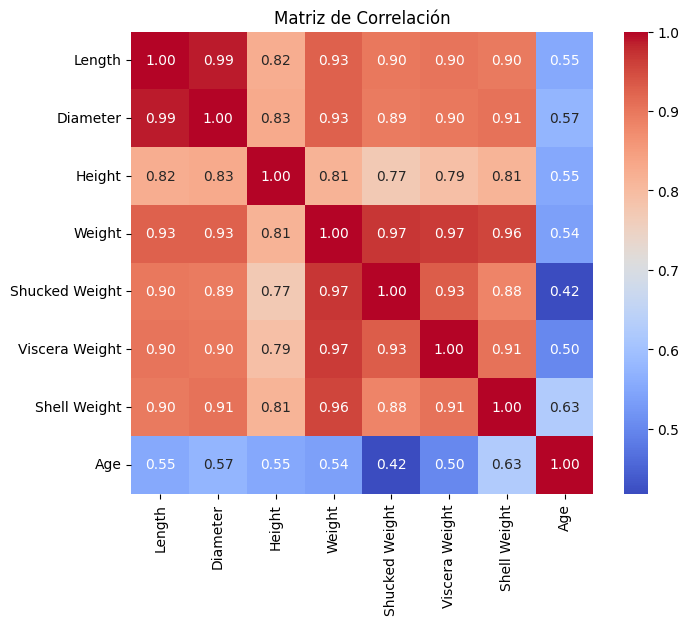

In [ ]:
# 4. Matriz de correlación y visualización
# Seleccionamos solo columnas numéricas
columnas_numericas = data.select_dtypes(include=[np.number])
matriz_corr = columnas_numericas.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Matriz de Correlación')
plt.show()

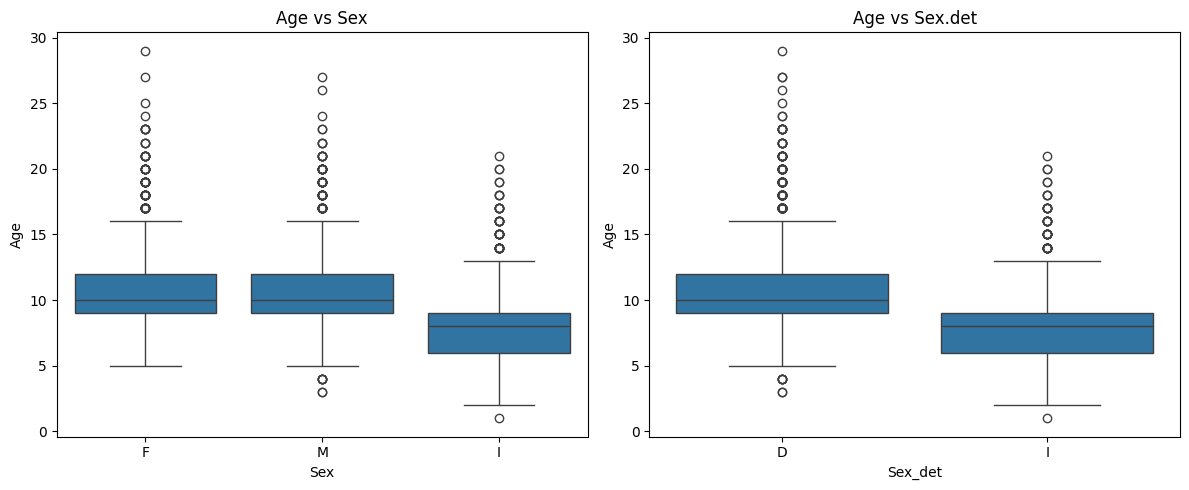

In [ ]:
# 5. Boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=data, x='Sex', y='Age', ax=axes[0])
axes[0].set_title('Age vs Sex')

sns.boxplot(data=data, x='Sex_det', y='Age', ax=axes[1])
axes[1].set_title('Age vs Sex.det')

plt.tight_layout()
plt.show()

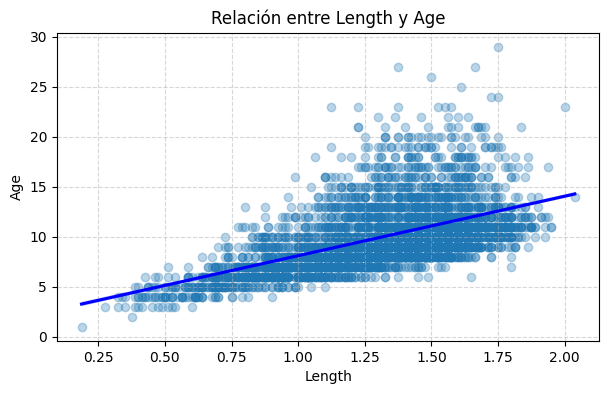

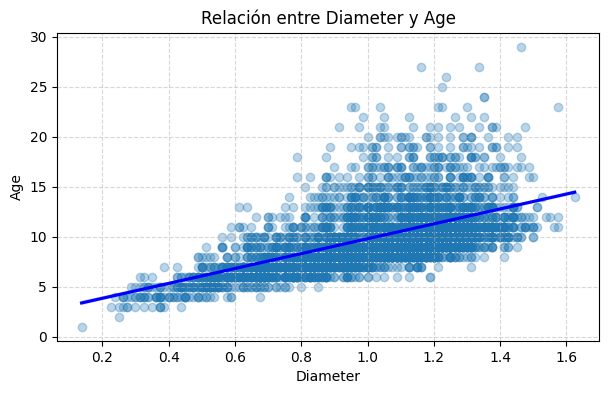

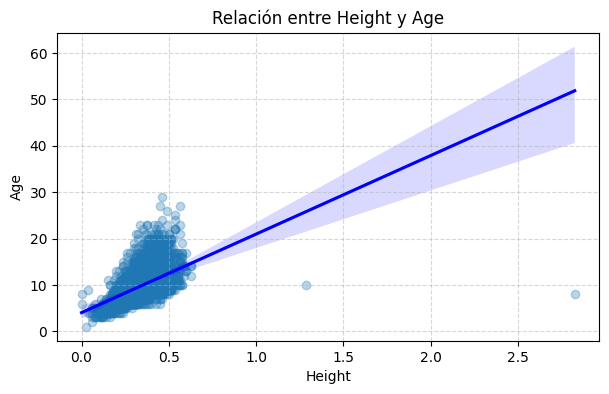

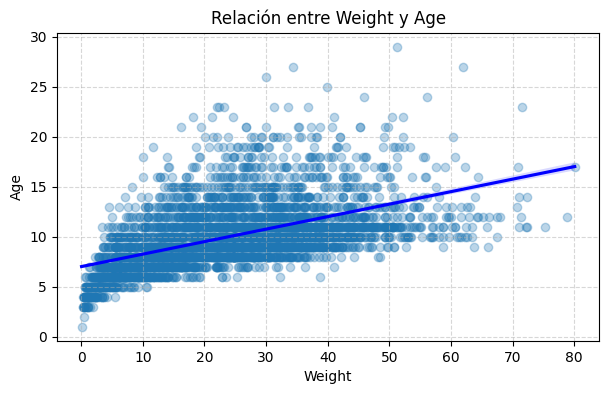

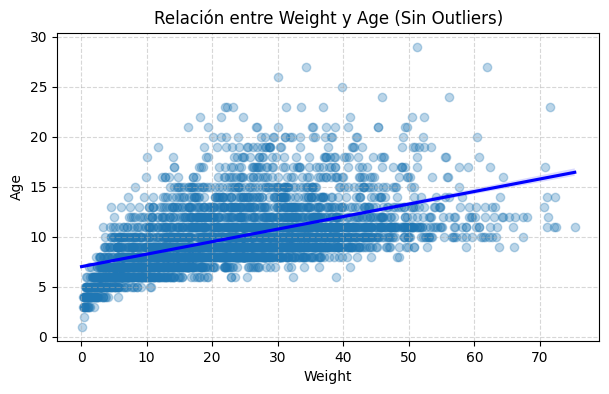

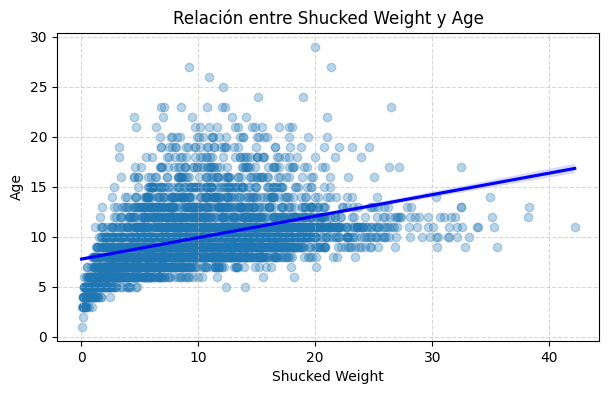

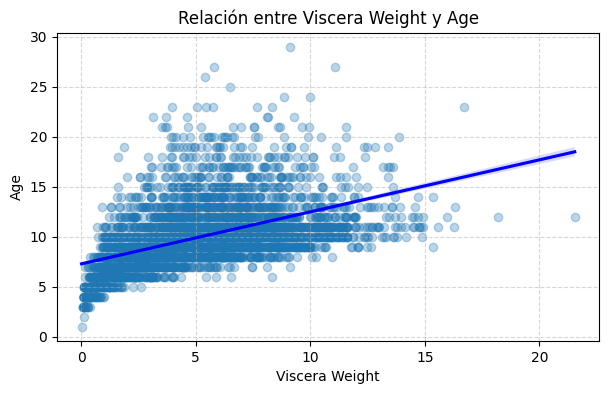

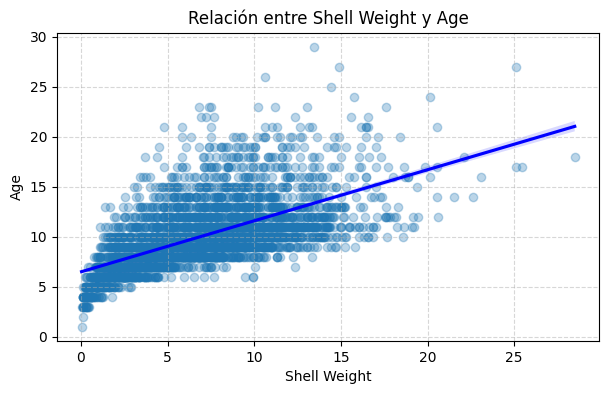

In [ ]:
# 6. Gráficos de dispersión con línea de tendencia
variables_x = [
    ('Length', data),
    ('Diameter', data),
    ('Height', data),
    ('Weight', data),
    ('Weight', data_sin_outliers_weight), # Gráfico sin outliers
    ('Shucked Weight', data),
    ('Viscera Weight', data),
    ('Shell Weight', data)
]

for var, df_plot in variables_x:
    plt.figure(figsize=(7, 4))
    sns.regplot(data=df_plot, x=var, y='Age', scatter_kws={'alpha':0.3}, line_kws={'color':'blue'})
    title_suffix = ' (Sin Outliers)' if df_plot is data_sin_outliers_weight else ''
    plt.title(f'Relación entre {var} y Age{title_suffix}')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

In [1]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 8. Preparar datos
variables_predictoras = [
    'Length', 'Diameter', 'Height', 'Weight',
    'Shucked Weight', 'Viscera Weight', 'Shell Weight', 'Sex_det'
]

X = pd.get_dummies(data[variables_predictoras], drop_first=True)
y = data['Age']

# 9. Dividir en conjunto de entrenamiento y prueba (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 10. Escalar las variables (Lasso penaliza según la escala,
# por lo que las variables deben tener media 0 y desviación estándar 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 11. Entrenar Lasso
lasso_cv = LassoCV(cv=5, random_state=42).fit(X_train_scaled, y_train)

print(f"Mejor parámetro Alpha encontrado: {lasso_cv.alpha_:.4f}")

# 12. Ver qué coeficientes sobrevivieron
seleccion_variables = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': lasso_cv.coef_
})

print("\nCoeficientes del Modelo Lasso (Variables Seleccionadas)")
variables_seleccionadas = seleccion_variables[seleccion_variables['Coeficiente'] != 0]
print(variables_seleccionadas)

print(f"\nVariables descartadas (coeficiente en cero): {list(seleccion_variables[seleccion_variables['Coeficiente'] == 0]['Variable'])}")

# 13. Evaluar el desempeño del modelo final
y_pred = lasso_cv.predict(X_test_scaled)

print("\n--- Desempeño del Modelo Lasso ---")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.4f}")

NameError: name 'pd' is not defined

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold

# 1. Preparar datos (¡aquí puedes incluir todas las variables de peso sin miedo!)
variables_predictoras = [
    'Length', 'Diameter', 'Height', 'Weight',
    'Shucked Weight', 'Viscera Weight', 'Shell Weight', 'Sex_det'
]

X = pd.get_dummies(data[variables_predictoras], drop_first=True)
y = data['Age']

# 2. Configurar el modelo de Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 3. Configurar la Validación Cruzada (K-Fold de 5 particiones)
cv = KFold(n_splits=10, shuffle=True, random_state=42)

# 4. Calcular el R² en cada iteración de la validación cruzada
scores_r2 = cross_val_score(rf_model, X, y, cv=cv, scoring='r2')

print("--- Desempeño de Random Forest con Validación Cruzada ---")
print(f"R² en cada Fold: {np.round(scores_r2, 4)}")
print(f"R² Promedio final: {scores_r2.mean():.4f} (Desviación estándar: +/- {scores_r2.std():.4f})")

--- Desempeño de Random Forest con Validación Cruzada ---
R² en cada Fold: [0.5421 0.5123 0.5848 0.571  0.5097 0.5293 0.5187 0.54   0.4976 0.5697]
R² Promedio final: 0.5375 (Desviación estándar: +/- 0.0280)
